In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned dataset
sales_data = np.load("../data/processed/cleaned_sales.npz")

# Extract required arrays
quantity_arr = sales_data["quantity"]
unitprice_arr = sales_data["unitprice"]
stockcode_arr = sales_data["stockcode"]
country_arr = sales_data["country"]
invoice_date_arr = sales_data["invoice_data"]

# Calculate revenue
revenue = quantity_arr * unitprice_arr

print("Dataset Loaded Successfully!")
print(f"Total Records: {len(revenue):,}")

Dataset Loaded Successfully!
Total Records: 530,104


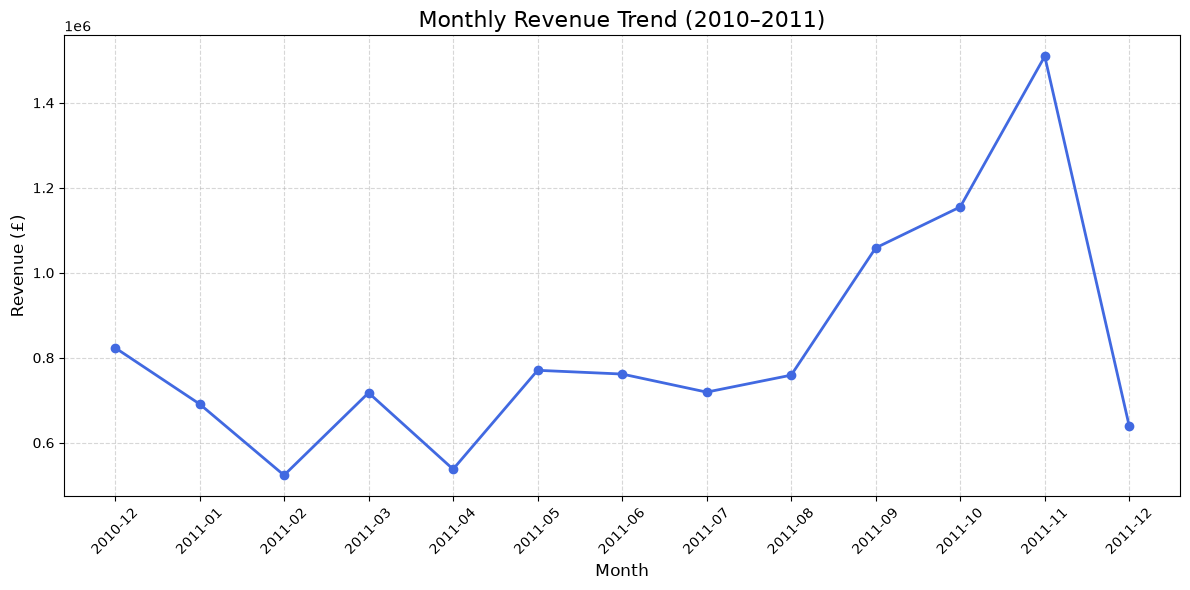

In [2]:
# ==================================================
#  MONTHLY REVENUE TREND
# ==================================================

# 1. Convert dates into year-month format
months = invoice_date_arr.astype("datetime64[M]")

# 2. Identify unique months
unique_months = np.unique(months)

# 3. Calculate monthly revenue
monthly_revenue = []

for month in unique_months:

    month_mask = months == month

    total = np.sum(revenue[month_mask])

    monthly_revenue.append(total)

monthly_revenue = np.array(monthly_revenue)

# ==================================================
# CREATE LINE CHART
# ==================================================

plt.figure(figsize=(12, 6))

plt.plot(
    unique_months.astype(str),
    monthly_revenue,
    marker="o",
    linewidth=2,
    color="royalblue"
)

plt.title("Monthly Revenue Trend (2010–2011)", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (£)", fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()

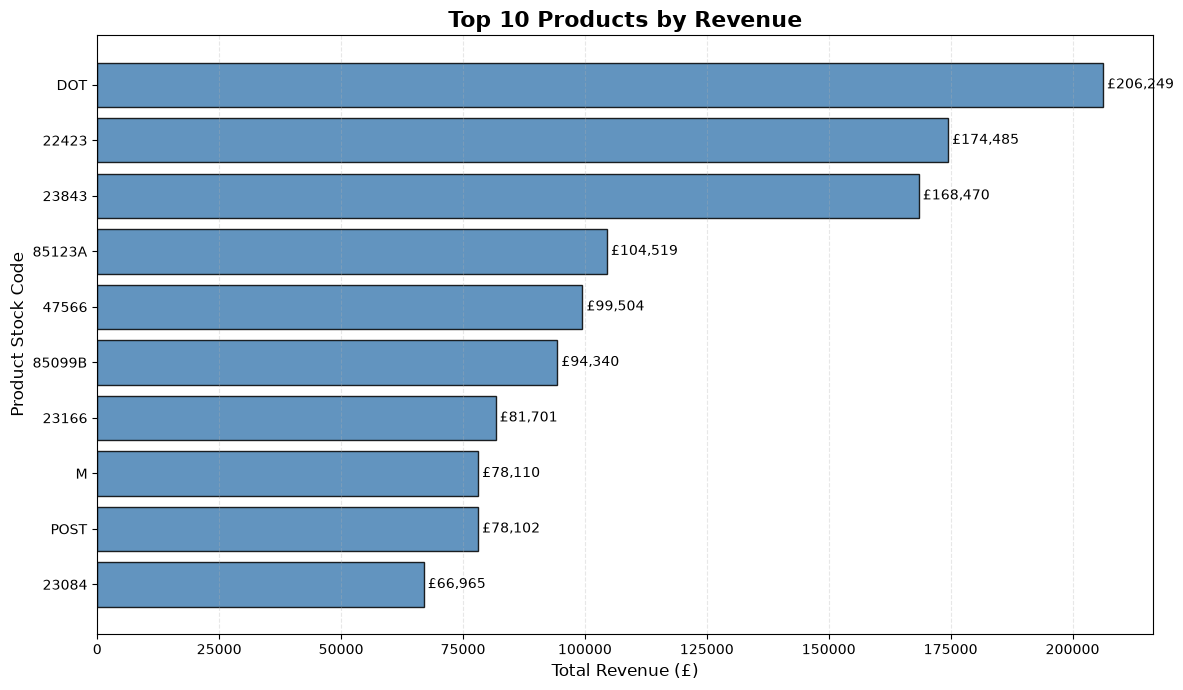

In [4]:
# ==================================================
#  TOP 10 PRODUCTS BY REVENUE
# ==================================================

# 1. Identify unique products
unique_products = np.unique(stockcode_arr)

# 2. Calculate revenue for each product
product_revenue = []

for product in unique_products:

    # Select transactions for the current product
    product_mask = stockcode_arr == product

    # Calculate total product revenue
    total = np.sum(revenue[product_mask])

    product_revenue.append(total)

# Convert list to NumPy array
product_revenue = np.array(product_revenue)

# ==================================================
# 3. IDENTIFY TOP 10 PRODUCTS
# ==================================================

top_10_indices = np.argsort(product_revenue)[-10:][::-1]

top_products = unique_products[top_10_indices]
top_revenue = product_revenue[top_10_indices]

# ==================================================
# 4. CREATE HORIZONTAL BAR CHART
# ==================================================

plt.figure(figsize=(12, 7))

plt.barh(
    top_products[::-1],
    top_revenue[::-1],
    color="steelblue",
    edgecolor="black",
    alpha=0.85
)

# Chart title and labels
plt.title(
    "Top 10 Products by Revenue",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Revenue (£)", fontsize=12)
plt.ylabel("Product Stock Code", fontsize=12)

# Add revenue labels to each bar
for index, value in enumerate(top_revenue[::-1]):
    plt.text(
        value,
        index,
        f" £{value:,.0f}",
        va="center",
        fontsize=10
    )

# Improve chart appearance
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    "../outputs/charts/top_10_products_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

# Display chart
plt.show()

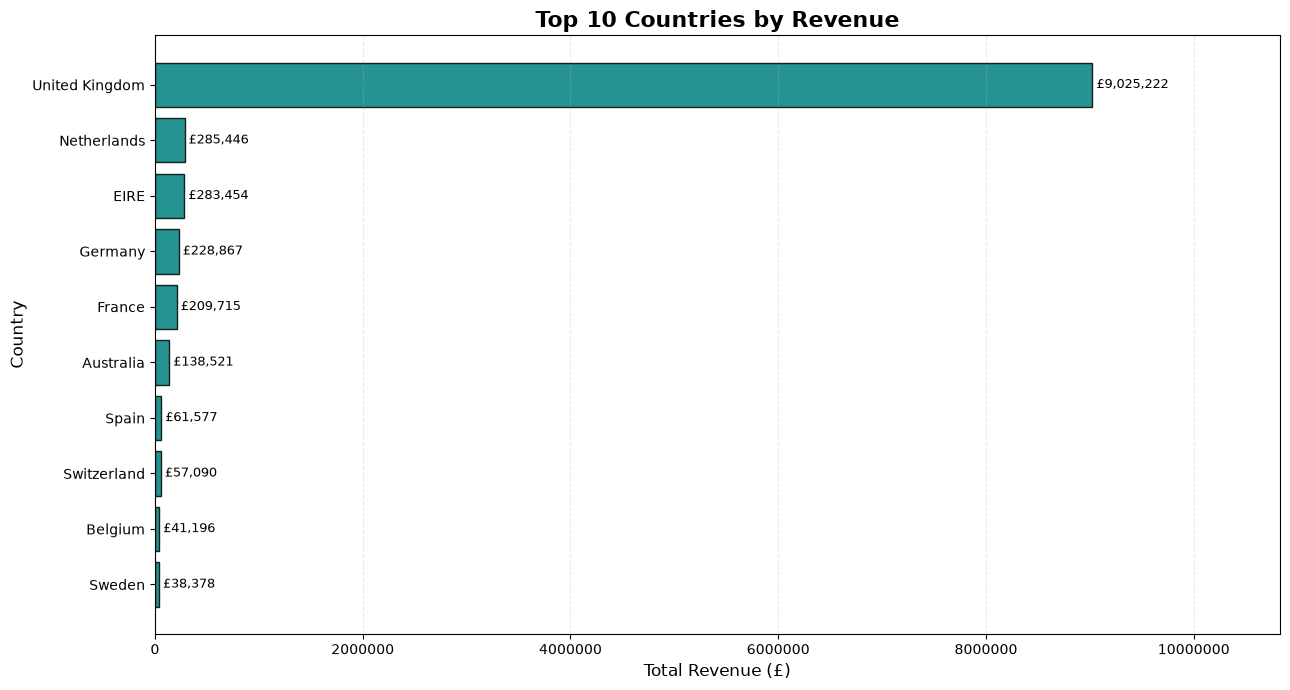

In [5]:
# ==================================================
# TOP 10 COUNTRIES BY REVENUE
# ==================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Identify unique countries
unique_countries = np.unique(country_arr)

# 2. Calculate revenue for each country
country_revenue = []

for country in unique_countries:

    # Select transactions belonging to this country
    country_mask = country_arr == country

    # Calculate total country revenue
    total = np.sum(revenue[country_mask])

    country_revenue.append(total)

# Convert list to NumPy array
country_revenue = np.array(country_revenue)

# ==================================================
# 3. IDENTIFY TOP 10 COUNTRIES
# ==================================================

top_10_indices = np.argsort(country_revenue)[-10:][::-1]

top_countries = unique_countries[top_10_indices]
top_revenue = country_revenue[top_10_indices]

# ==================================================
# 4. CREATE HORIZONTAL BAR CHART
# ==================================================

plt.figure(figsize=(13, 7))

bars = plt.barh(
    top_countries[::-1],
    top_revenue[::-1],
    color="teal",
    edgecolor="black",
    alpha=0.85
)

# Chart title and labels
plt.title(
    "Top 10 Countries by Revenue",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Revenue (£)", fontsize=12)
plt.ylabel("Country", fontsize=12)

# Display revenue labels
for index, value in enumerate(top_revenue[::-1]):
    plt.text(
        value,
        index,
        f" £{value:,.0f}",
        va="center",
        fontsize=9
    )

# Improve appearance
plt.ticklabel_format(style="plain", axis="x")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.margins(x=0.20)
plt.tight_layout()

# ==================================================
# 5. SAVE CHART
# ==================================================

charts_dir = Path("../outputs/charts")
charts_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_dir / "top_10_countries_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

========== CUSTOMER SEGMENTATION REPORT ==========
Low Spending Customers: 1,432
Medium Spending Customers: 1,431
High Spending Customers: 1,475


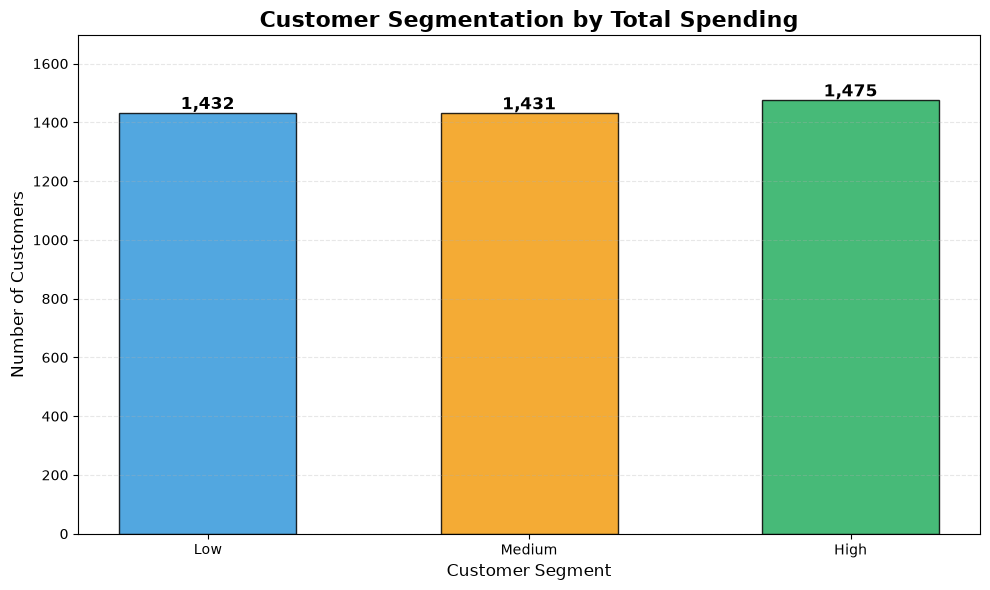

In [6]:
# ==================================================
#  CUSTOMER SEGMENTATION VISUALIZATION
# ==================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# 1. FILTER CUSTOMERS WITH VALID IDs
# ==================================================

customer_id_arr = sales_data["customer_id"]

# Identify valid customer records
valid_customer_mask = ~np.isnan(customer_id_arr)

# Filter customer IDs and corresponding revenue
valid_customer_ids = customer_id_arr[valid_customer_mask]
valid_revenue = revenue[valid_customer_mask]

# ==================================================
# 2. CALCULATE CUSTOMER-WISE SPENDING
# ==================================================

unique_customers, customer_indices = np.unique(
    valid_customer_ids,
    return_inverse=True
)

# Sum revenue for each customer
customer_spending = np.bincount(
    customer_indices,
    weights=valid_revenue
)

# ==================================================
# 3. CALCULATE SPENDING THRESHOLDS
# ==================================================

low_threshold = np.percentile(customer_spending, 33)
high_threshold = np.percentile(customer_spending, 66)

# Assign spending categories
customer_segments = np.where(
    customer_spending <= low_threshold,
    "Low",
    np.where(
        customer_spending <= high_threshold,
        "Medium",
        "High"
    )
)

# ==================================================
# 4. COUNT CUSTOMERS IN EACH SEGMENT
# ==================================================

segment_names = np.array(["Low", "Medium", "High"])

segment_counts = np.array([
    np.sum(customer_segments == segment)
    for segment in segment_names
])

print("========== CUSTOMER SEGMENTATION REPORT ==========")

for segment, count in zip(segment_names, segment_counts):
    print(f"{segment} Spending Customers: {count:,}")

# ==================================================
# 5. CREATE BAR CHART
# ==================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    segment_names,
    segment_counts,
    color=["#3498db", "#f39c12", "#27ae60"],
    edgecolor="black",
    width=0.55,
    alpha=0.85
)

# Add customer counts above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# ==================================================
# 6. CHART FORMATTING
# ==================================================

plt.title(
    "Customer Segmentation by Total Spending",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Segment", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

plt.ylim(0, max(segment_counts) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

# ==================================================
# 7. SAVE CHART
# ==================================================

charts_dir = Path("../outputs/charts")
charts_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_dir / "customer_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

========== REVENUE DISTRIBUTION REPORT ==========
Total Transaction Lines : 530,104
Minimum Revenue         : £0.00
Maximum Revenue         : £168,469.60
Mean Revenue            : £20.12
Median Revenue          : £9.90
25th Percentile         : £3.75
75th Percentile         : £17.70
99th Percentile         : £183.60

Records Displayed: 524,825
Records Excluded from Chart: 5,279


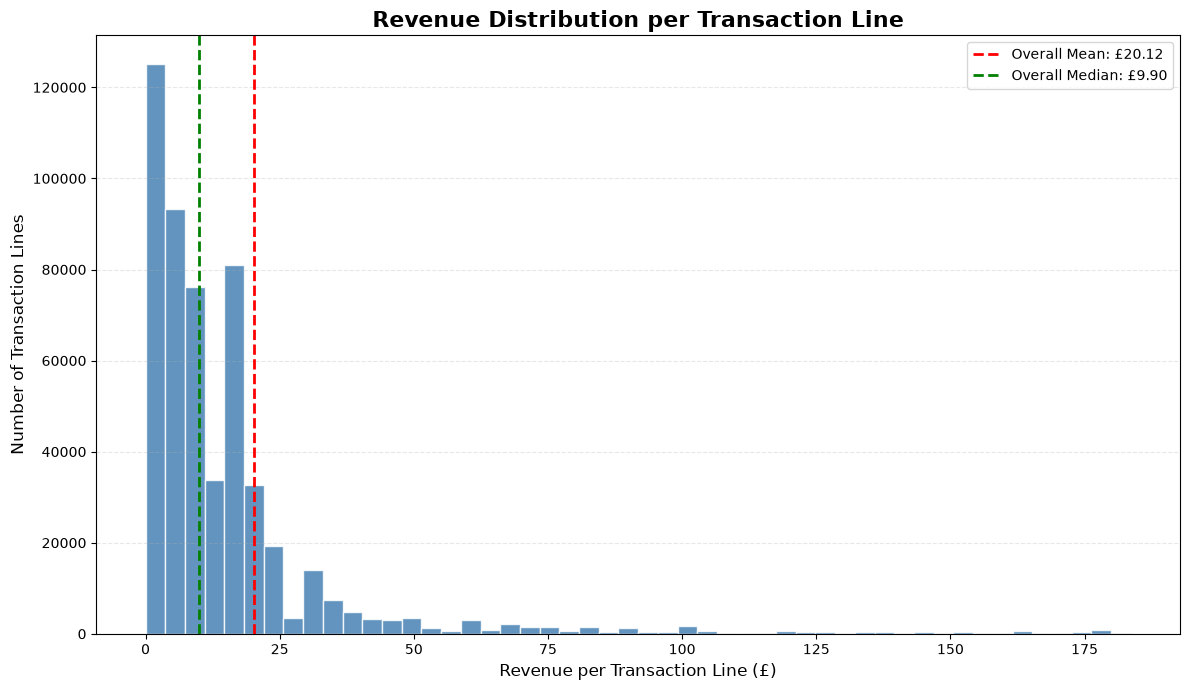

In [7]:
# ==================================================
#  REVENUE DISTRIBUTION ANALYSIS
# ==================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# 1. ANALYZE REVENUE DISTRIBUTION
# ==================================================

# Calculate revenue statistics
mean_revenue = np.mean(revenue)
median_revenue = np.median(revenue)
min_revenue = np.min(revenue)
max_revenue = np.max(revenue)

# Calculate revenue percentiles
p25 = np.percentile(revenue, 25)
p75 = np.percentile(revenue, 75)
p99 = np.percentile(revenue, 99)

print("========== REVENUE DISTRIBUTION REPORT ==========")

print(f"Total Transaction Lines : {len(revenue):,}")
print(f"Minimum Revenue         : £{min_revenue:,.2f}")
print(f"Maximum Revenue         : £{max_revenue:,.2f}")
print(f"Mean Revenue            : £{mean_revenue:,.2f}")
print(f"Median Revenue          : £{median_revenue:,.2f}")
print(f"25th Percentile         : £{p25:,.2f}")
print(f"75th Percentile         : £{p75:,.2f}")
print(f"99th Percentile         : £{p99:,.2f}")

# ==================================================
# 2. PREPARE DATA FOR VISUALIZATION
# ==================================================

# Focus on the bottom 99% of revenue values
# to improve chart readability
filtered_revenue = revenue[revenue <= p99]

print(f"\nRecords Displayed: {len(filtered_revenue):,}")
print(f"Records Excluded from Chart: {len(revenue) - len(filtered_revenue):,}")

# ==================================================
# 3. CREATE REVENUE DISTRIBUTION HISTOGRAM
# ==================================================

plt.figure(figsize=(12, 7))

plt.hist(
    filtered_revenue,
    bins=50,
    color="steelblue",
    edgecolor="white",
    alpha=0.85
)

# Add mean and median reference lines
plt.axvline(
    mean_revenue,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Mean: £{mean_revenue:,.2f}"
)

plt.axvline(
    median_revenue,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Overall Median: £{median_revenue:,.2f}"
)

# ==================================================
# 4. CHART FORMATTING
# ==================================================

plt.title(
    "Revenue Distribution per Transaction Line",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Revenue per Transaction Line (£)", fontsize=12)
plt.ylabel("Number of Transaction Lines", fontsize=12)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.legend()

plt.tight_layout()

# ==================================================
# 5. SAVE CHART
# ==================================================

charts_dir = Path("../outputs/charts")
charts_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_dir / "revenue_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

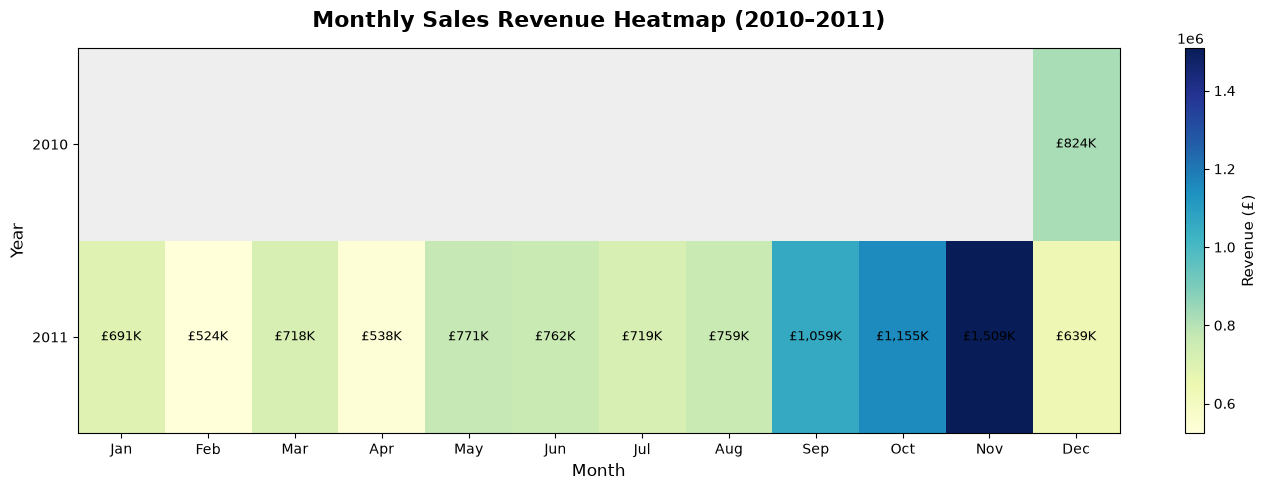

========== HEATMAP VERIFICATION ==========
Heatmap Total Revenue: £10,666,684.54
Overall Total Revenue: £10,666,684.54
Revenue Verification: True


In [8]:
# ==================================================
#  MONTHLY SALES PERFORMANCE HEATMAP
# ==================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==================================================
# 1. EXTRACT YEAR AND MONTH
# ==================================================

# Convert invoice dates to month precision
invoice_months = invoice_date_arr.astype("datetime64[M]")

# Extract years
years = invoice_months.astype("datetime64[Y]").astype(int) + 1970

# Extract month numbers (1-12)
month_numbers = (
    invoice_months.astype(int) % 12
) + 1

# Identify unique years
unique_years = np.unique(years)

# ==================================================
# 2. CREATE REVENUE MATRIX
# ==================================================

# Rows = Years, Columns = Months
heatmap_data = np.full(
    (len(unique_years), 12),
    np.nan,
    dtype=float
)

# Calculate revenue for each year and month
for i, year in enumerate(unique_years):

    for month in range(1, 13):

        # Select transactions for the year and month
        month_mask = (
            (years == year)
            & (month_numbers == month)
        )

        # Calculate revenue if records exist
        if np.any(month_mask):
            heatmap_data[i, month - 1] = np.sum(
                revenue[month_mask]
            )

# ==================================================
# 3. CREATE HEATMAP
# ==================================================

plt.figure(figsize=(14, 5))

# Display missing months separately
masked_data = np.ma.masked_invalid(heatmap_data)

cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad(color="#eeeeee")

im = plt.imshow(
    masked_data,
    cmap=cmap,
    aspect="auto"
)

# ==================================================
# 4. ADD LABELS
# ==================================================

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

plt.xticks(
    ticks=np.arange(12),
    labels=month_names
)

plt.yticks(
    ticks=np.arange(len(unique_years)),
    labels=unique_years
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Year", fontsize=12)

plt.title(
    "Monthly Sales Revenue Heatmap (2010–2011)",
    fontsize=16,
    fontweight="bold",
    pad=15
)

# ==================================================
# 5. DISPLAY REVENUE VALUES IN CELLS
# ==================================================

for i in range(len(unique_years)):

    for j in range(12):

        value = heatmap_data[i, j]

        if not np.isnan(value):

            plt.text(
                j,
                i,
                f"£{value / 1000:,.0f}K",
                ha="center",
                va="center",
                fontsize=9,
                color="black"
            )

# ==================================================
# 6. ADD COLORBAR
# ==================================================

cbar = plt.colorbar(im)
cbar.set_label("Revenue (£)", fontsize=11)

# ==================================================
# 7. SAVE CHART
# ==================================================

charts_dir = Path("../outputs/charts")
charts_dir.mkdir(parents=True, exist_ok=True)

plt.tight_layout()

plt.savefig(
    charts_dir / "monthly_sales_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==================================================
# 8. VERIFY HEATMAP REVENUE
# ==================================================

heatmap_total = np.nansum(heatmap_data)
overall_total = np.sum(revenue)

print("========== HEATMAP VERIFICATION ==========")

print(f"Heatmap Total Revenue: £{heatmap_total:,.2f}")
print(f"Overall Total Revenue: £{overall_total:,.2f}")

print(
    "Revenue Verification:",
    np.isclose(heatmap_total, overall_total)
)